# DHB-XR: Features and Use-Cases Demo

This notebook demonstrates the main features and use-cases of **dhb_xr** (DHB Extended Representations) for SE(3) invariant trajectory encoding. Inspired by MATLAB Live Script workflows, we walk through:

1. **Constructing a 6-DOF trajectory** — position and orientation over time
2. **Encode and decode** — DHB-DR invariants and reconstruction
3. **SE(3) invariance** — invariants are unchanged under global rigid transforms
4. **DHB-DR vs DHB-QR** — Euler vs quaternion-based invariants
5. **DHB-TI (time-invariant)** — reparameterization by geometric progress
6. **Trajectory adaptation** — retargeting to a new initial pose
7. **Visualization** — 3D trajectories and invariant time series
8. **Optional: VLA tokenization** — discrete tokens for action representation

**Requirements:** `numpy`, `scipy`, `matplotlib`. Optional: `torch` for tokenization.

---
## Setup and imports

The first cell adds the repo **src** to `sys.path` if **dhb_xr** is not installed, so the notebook works when run from the repo (e.g. **pixi run notebook** from the dhb_xr root). If you get `ModuleNotFoundError: No module named 'dhb_xr'`, run this cell first and ensure the kernel's working directory is the **dhb_xr** repo root, or start Jupyter from the repo: `pixi run notebook`.

In [1]:
# Ensure dhb_xr is importable: add repo src to path if not installed (e.g. when using pixi run notebook)
import sys
from pathlib import Path

if "dhb_xr" not in sys.modules:
    def _find_src():
        for p in [Path.cwd()] + list(Path.cwd().parents):
            for root in [p, p / "dhb_xr"]:
                src = root / "src"
                if (root / "pyproject.toml").exists() and (src / "dhb_xr").exists():
                    return src
        return None
    src = _find_src()
    if src is not None and str(src) not in sys.path:
        sys.path.insert(0, str(src))

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

from dhb_xr import encode_dhb_dr, decode_dhb_dr
from dhb_xr.core.types import DHBMethod
from dhb_xr.core import geometry as geom
from dhb_xr.encoder.dhb_ti import compute_progress, resample_by_progress, encode_dhb_dr_ti
from dhb_xr.visualization.plot import plot_se3_trajectory, plot_se3_trajectories, plot_invariants, draw_box, draw_frame
from dhb_xr.optimization.casadi_solver import generate_trajectory, HAS_CASADI

np.random.seed(42)
plt.rcParams['figure.figsize'] = (8, 5)

---
## 1. Construct a 6-DOF trajectory

We build a smooth SE(3) trajectory: **position** as a parametric curve (e.g. spiral or sinusoids) and **orientation** as time-varying Euler angles converted to quaternions (wxyz). This mimics typical motion data from robots or motion capture.

- **Position:** $x(t)$, $y(t)$, $z(t)$ — e.g. exponential + sinusoids
- **Orientation:** roll, pitch, yaw (Euler ZYX) → rotation matrix → quaternion (wxyz)

The result is `positions` (N×3) and `quaternions` (N×4) with **wxyz** convention (scalar first).

In [2]:
def build_demo_trajectory(n=80, dt=0.05):
    """Build a 6-DOF trajectory: position curve + orientation over time."""
    t = np.linspace(0, (n - 1) * dt, n)
    # Position: smooth curve (inspired by mainDHB.m)
    x = 0.1 * np.exp(t * 0.3)
    y = 0.5 + 0.3 * np.sin(t * 2)
    z = 0.2 * np.cos(t)
    positions = np.column_stack([x, y, z])
    # Orientation: roll, pitch, yaw (rad) -> quaternion wxyz
    roll = 0.3 * np.sin(t)
    pitch = 0.2 * np.cos(t * 1.5)
    yaw = 0.1 * t
    quaternions = np.array([
        geom.rot_to_quat(
            geom.euler_to_rot(np.array([roll[i], pitch[i], yaw[i]]))
        ) for i in range(n)
    ])
    return positions, quaternions

positions, quaternions = build_demo_trajectory(n=80)
print("Trajectory length:", len(positions))
print("Positions shape:", positions.shape, "| Quaternions shape:", quaternions.shape)
print("First position:", positions[0])
print("First quaternion (wxyz):", quaternions[0])

Trajectory length: 80
Positions shape: (80, 3) | Quaternions shape: (80, 4)
First position: [0.1 0.5 0.2]
First quaternion (wxyz): [0.99500417 0.         0.09983342 0.        ]


### Plot: 3D position trajectory

The curve shows the Cartesian path of the rigid body. Optionally we can draw orientation frames at sampled points.

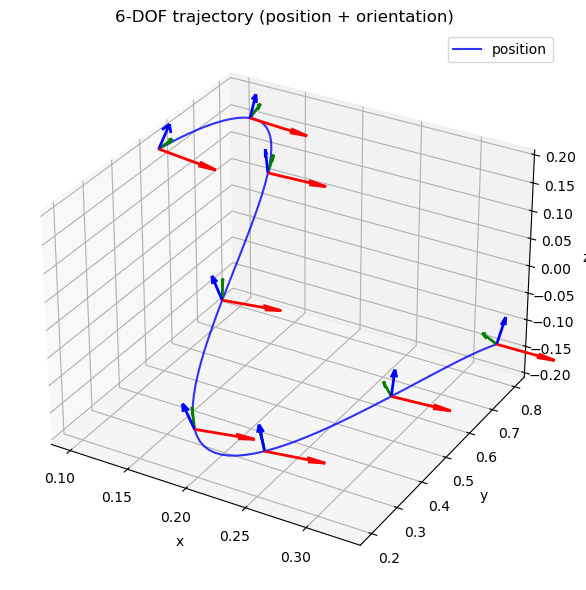

In [3]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
plot_se3_trajectory(positions, quaternions, ax=ax, title="6-DOF trajectory (position + orientation)", show_orientation=True)
ax.legend()
plt.tight_layout()
plt.show()

---
## 2. Encode and decode with DHB-DR

**DHB-DR** (double-reflection) computes *invariants* from the trajectory: for each step we get **linear invariants** (magnitude + Euler angles of the linear frame step) and **angular invariants** (magnitude + Euler angles of the angular step). These describe the motion in a way that is **independent of the global reference frame** (see next section).

- **Encode:** `encode_dhb_dr(positions, quaternions, ...)` → `linear_motion_invariants` (N′×4), `angular_motion_invariants` (N′×4), `initial_pose`
- **Decode:** `decode_dhb_dr(linear_inv, angular_inv, initial_pose, ...)` → `positions`, `quaternions` (reconstructed trajectory)

With default padding, the encoder output length N′ is slightly larger than N−2 so that decoding with `drop_padded=True` aligns with the original length convention.

In [4]:
out = encode_dhb_dr(
    positions, quaternions,
    method="pos",
    use_default_initial_frames=True,
    dhb_method=DHBMethod.DOUBLE_REFLECTION,
)
linear_inv = out["linear_motion_invariants"]
angular_inv = out["angular_motion_invariants"]
initial_pose = out["initial_pose"]

print("Encoded linear invariants shape:", linear_inv.shape)
print("Encoded angular invariants shape:", angular_inv.shape)
print("Initial pose position:", initial_pose["position"])

decoded = decode_dhb_dr(
    linear_inv, angular_inv, initial_pose,
    method="pos", dhb_method=DHBMethod.DOUBLE_REFLECTION, drop_padded=True,
)
pos_dec = decoded["positions"]
quat_dec = decoded["quaternions"]
print("Decoded positions shape:", pos_dec.shape)
print("Reconstruction error (position):", np.linalg.norm(pos_dec - positions[:len(pos_dec)]))
print("Reconstruction error (quat, geodesic approx):", np.mean([np.linalg.norm(geom.quat_relative_axis_angle(quat_dec[i], quaternions[i])) for i in range(len(quat_dec))]))

Encoded linear invariants shape: (82, 4)
Encoded angular invariants shape: (82, 4)
Initial pose position: [0.1 0.5 0.2]
Decoded positions shape: (80, 3)
Reconstruction error (position): 1.0307848268713797e-14
Reconstruction error (quat, geodesic approx): 2.723700601207636e-14


### Plot: Invariant time series

The **first column** of each invariant block is the **step magnitude** (translational and rotational); the remaining columns are orientation parameters (Euler angles in DHB-DR). These invariants fully describe the motion up to a global SE(3) frame.

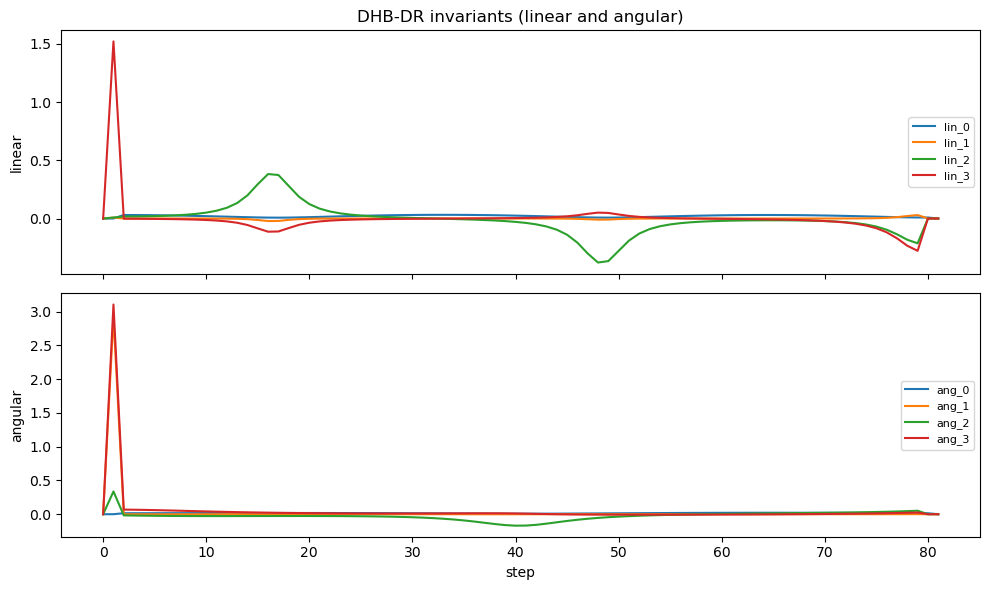

In [5]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(10, 6))
plot_invariants(linear_inv, angular_inv, ax=axes, title="DHB-DR invariants (linear and angular)")
plt.tight_layout()
plt.show()

---
## 3. SE(3) invariance

A key property of DHB invariants is **invariance to global SE(3) transforms**. If we apply the same rigid transformation (rotation $R$ and translation $t$) to every pose of the trajectory, the *invariant sequence* (magnitudes and relative frame structure) is **unchanged**.

So: *encode(original)* and *encode(transformed)* yield the same linear/angular invariant **magnitudes** (first column). This is useful for comparing motions regardless of where they were performed or how the world frame was defined.

In [6]:
def apply_se3(positions, quaternions, R, t):
    """Apply global SE(3): p' = R p + t, q' = R * q (rotation composition)."""
    p_new = (R @ positions.T).T + t
    q_new = np.array([geom.rot_to_quat(R @ geom.quat_to_rot(q)) for q in quaternions])
    return p_new, q_new

# Random SE(3) transform
axis = np.random.randn(3)
axis /= np.linalg.norm(axis)
R = geom.axis_angle_to_rot(axis * 0.5)
t_vec = np.array([0.2, -0.1, 0.15])
positions_tf, quaternions_tf = apply_se3(positions, quaternions, R, t_vec)

out_orig = encode_dhb_dr(positions, quaternions, method="pos", use_default_initial_frames=True, dhb_method=DHBMethod.DOUBLE_REFLECTION)
out_tf   = encode_dhb_dr(positions_tf, quaternions_tf, method="pos", use_default_initial_frames=True, dhb_method=DHBMethod.DOUBLE_REFLECTION)

lin_orig = out_orig["linear_motion_invariants"]
ang_orig = out_orig["angular_motion_invariants"]
lin_tf   = out_tf["linear_motion_invariants"]
ang_tf   = out_tf["angular_motion_invariants"]

match_lin = np.allclose(lin_orig[:, 0], lin_tf[:, 0])
match_ang = np.allclose(ang_orig[:, 0], ang_tf[:, 0])
print("Linear  magnitude invariant (first column) match:", match_lin)
print("Angular magnitude invariant (first column) match:", match_ang)
print("Max diff linear  mag:", np.max(np.abs(lin_orig[:, 0] - lin_tf[:, 0])))
print("Max diff angular mag:", np.max(np.abs(ang_orig[:, 0] - ang_tf[:, 0])))

Linear  magnitude invariant (first column) match: True
Angular magnitude invariant (first column) match: True
Max diff linear  mag: 1.5265566588595902e-16
Max diff angular mag: 1.5785983631388945e-16


### Plot: Original vs transformed trajectory

The two trajectories differ by a global rigid transform; their DHB invariant magnitudes are the same.

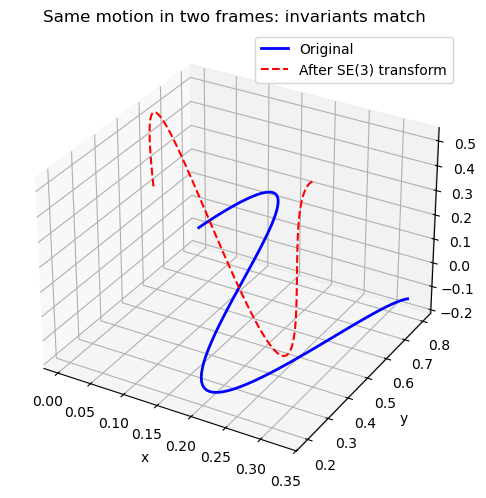

In [7]:
fig = plt.figure(figsize=(9, 5))
ax = fig.add_subplot(111, projection='3d')
ax.plot(positions[:, 0], positions[:, 1], positions[:, 2], 'b-', label='Original', linewidth=2)
ax.plot(positions_tf[:, 0], positions_tf[:, 1], positions_tf[:, 2], 'r--', label='After SE(3) transform', linewidth=1.5)
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
ax.set_title('Same motion in two frames: invariants match')
ax.legend()
plt.tight_layout()
plt.show()

---
## 4. DHB-DR vs DHB-QR

- **DHB-DR** uses **Euler angles** for the relative orientation at each step → 4 values per component (magnitude + 3 Euler). Can suffer from gimbal lock.
- **DHB-QR** uses **quaternions** for the relative rotation → 5 values per component (magnitude + 4D quaternion, with unit norm). Singularity-free and convenient for geodesic losses.

Same trajectory encoded with both yields different *shapes* (e.g. linear invariants (N,4) vs (N,5)); the *information* is equivalent up to representation.

In [8]:
from dhb_xr.encoder.dhb_dr import encode_dhb_dr
from dhb_xr.encoder.dhb_qr import encode_dhb_qr

out_dr = encode_dhb_dr(positions, quaternions, method="pos", use_default_initial_frames=True, dhb_method=DHBMethod.DOUBLE_REFLECTION)
out_qr = encode_dhb_qr(positions, quaternions, method="pos", use_default_initial_frames=True)

print("DHB-DR linear invariants shape:", out_dr["linear_motion_invariants"].shape)
print("DHB-QR linear invariants shape:", out_qr["linear_motion_invariants"].shape)
print("DHB-DR: 4 values per step (magnitude + Euler). DHB-QR: 5 values per step (magnitude + quat).")

DHB-DR linear invariants shape: (82, 4)
DHB-QR linear invariants shape: (82, 5)
DHB-DR: 4 values per step (magnitude + Euler). DHB-QR: 5 values per step (magnitude + quat).


---
## 5. DHB-TI: Time-invariant reparameterization

Raw DHB invariants depend on **how densely** the trajectory is sampled in time: faster execution or lower frame rate changes step sizes and thus magnitudes. **DHB-TI** reparameterizes the trajectory by a **geometric progress variable** (e.g. arc-length or hybrid with rotation) and resamples at **uniform progress knots** before encoding. The resulting invariants are (approximately) **independent of execution speed and sampling rate**.

- **Progress:** translation (arc-length), angular (rotation magnitude), or **hybrid** $\sigma_{i+1} = \sigma_i + \alpha\|\Delta p_i\| + (1-\alpha)\|\Delta r_i\|$
- **Resample:** uniform $\sigma_k = k \Sigma/(M-1)$, interpolate positions (spline) and orientations (SLERP)
- **Encode:** apply DHB-DR (or DHB-QR) to the resampled sequence → `encode_dhb_dr_ti(...)`

In [9]:
M = 40
progress = compute_progress(positions, quaternions, kind="hybrid", alpha=0.5)
pos_ti, quat_ti = resample_by_progress(positions, quaternions, M, progress_kind="hybrid", alpha=0.5)

print("Total progress (hybrid, α=0.5):", progress[-1])
print("Resampled trajectory length:", M)

out_ti = encode_dhb_dr_ti(positions, quaternions, M, progress_kind="hybrid", alpha=0.5,
                          method="pos", use_default_initial_frames=True, dhb_method=DHBMethod.DOUBLE_REFLECTION)
print("DHB-TI (DR) linear invariants shape:", out_ti["linear_motion_invariants"].shape)

Total progress (hybrid, α=0.5): 1.447269331007317
Resampled trajectory length: 40
DHB-TI (DR) linear invariants shape: (42, 4)


### Plot: Original vs time-invariant resampled path

Resampled poses lie on the same geometric path but at uniform progress; encoding this sequence gives timing-robust invariants.

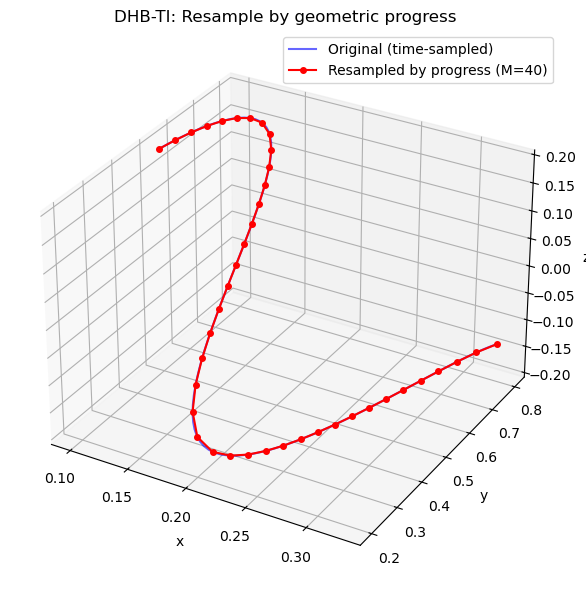

In [10]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot(positions[:, 0], positions[:, 1], positions[:, 2], 'b-', alpha=0.6, label='Original (time-sampled)')
ax.plot(pos_ti[:, 0], pos_ti[:, 1], pos_ti[:, 2], 'ro-', markersize=4, label=f'Resampled by progress (M={M})')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
ax.set_title('DHB-TI: Resample by geometric progress')
ax.legend()
plt.tight_layout()
plt.show()

---
## 6. Trajectory adaptation (retargeting)

We can **adapt** a demo trajectory to a **new initial pose** (and optionally goal): resample the demo, encode to invariants, then **decode** from the new initial pose. The motion *style* (invariants) is preserved while the start (and optionally end) pose is changed — useful for transferring a motion to a different robot or workspace.

**How it works:**
- The demo trajectory is resampled and encoded to DHB invariants
- A **CasADi NLP** solves for new invariants that satisfy boundary constraints while minimizing deviation from the demo
- If CasADi is unavailable or the NLP fails, a smooth interpolation fallback is used

`generate_trajectory(demo_pos, demo_quat, pose_init, pose_goal, traj_length, ...)` returns the adapted positions and quaternions.

The solver reports which method was used: `"casadi"` for the NLP solver, `"interpolation"` for the fallback.

In [11]:
# Check if CasADi solver is available
print(f"CasADi available: {HAS_CASADI}")

# Example 1: Simple position offset (same orientation)
pose_init = {"position": positions[0].copy(), "quaternion": quaternions[0].copy()}
pose_goal = {
    "position": positions[-1].copy() + np.array([0.15, 0.1, 0.05]),
    "quaternion": quaternions[-1].copy(),
}
traj_length = 80

result = generate_trajectory(
    positions, quaternions,
    pose_init, pose_goal,
    traj_length=traj_length,
    smoothing=False,
    dhb_method=DHBMethod.DOUBLE_REFLECTION,
    use_casadi=True,  # Try CasADi solver first
    verbose=False,
)
adapted_pos = result["adapted_pos_data"]
adapted_quat = result["adapted_quat_data"]

print(f"Solver used: {result['solver']}")
print(f"Adapted trajectory length: {len(adapted_pos)}")
print(f"Start matches init: {np.allclose(adapted_pos[0], pose_init['position'], atol=1e-3)}")
print(f"End matches goal: {np.allclose(adapted_pos[-1], pose_goal['position'], atol=1e-3)}")

CasADi available: True

******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

Solver used: casadi
Adapted trajectory length: 80
Start matches init: True
End matches goal: True


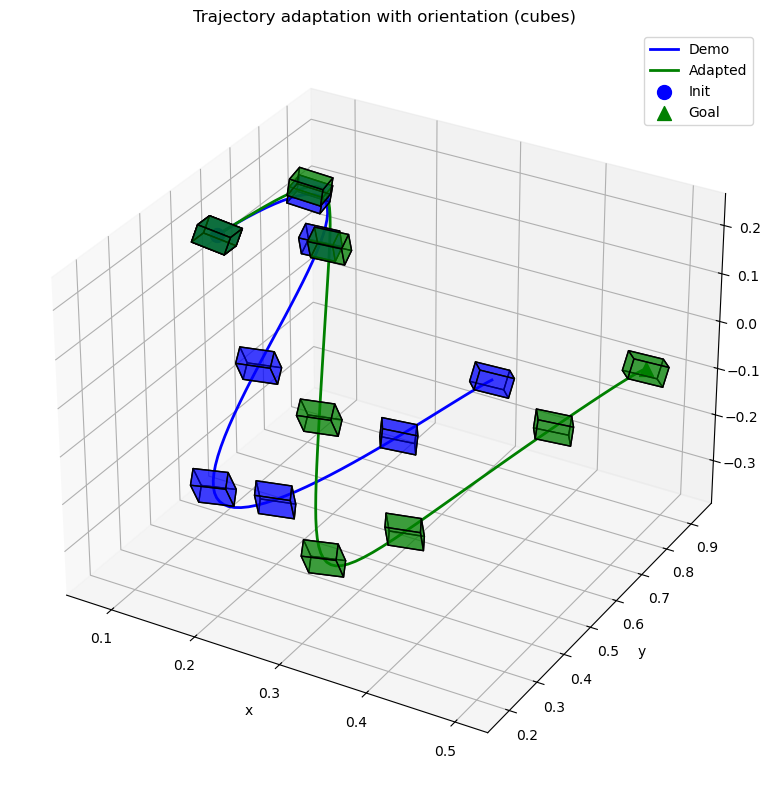

Solver used: casadi
Start position matches: True
End position matches: True


In [12]:
# Plot with orientation cubes to visualize rotation adaptation
from dhb_xr.visualization.plot import plot_se3_trajectories, draw_box, draw_frame

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot demo trajectory with blue cubes
plot_se3_trajectories(
    {"Demo": {"positions": positions, "quaternions": quaternions},
     "Adapted": {"positions": adapted_pos, "quaternions": adapted_quat}},
    ax=ax,
    show_orientation=True,
    vis_type="cube",
    box_size_scale=0.04,
    num_frames=8,
    title="Trajectory adaptation with orientation (cubes)",
    show_legend=True,
)

# Mark init and goal
ax.scatter(*pose_init["position"], color='blue', s=100, marker='o', label='Init', zorder=10)
ax.scatter(*pose_goal["position"], color='green', s=100, marker='^', label='Goal', zorder=10)

ax.legend()
plt.tight_layout()
plt.show()

print(f"Solver used: {result['solver']}")
print(f"Start position matches: {np.allclose(adapted_pos[0], pose_init['position'], atol=1e-3)}")
print(f"End position matches: {np.allclose(adapted_pos[-1], pose_goal['position'], atol=1e-3)}")

### 6.1 Diverse trajectory adaptation examples

Let's demonstrate the **generality** of trajectory adaptation with different scenarios:
1. **Large position offset** — move the entire motion to a different location
2. **Different start and goal** — stretch or compress the motion
3. **Rotation change** — apply a different initial orientation

The invariants capture the *shape* of the motion, so the adapted trajectory preserves the motion style.

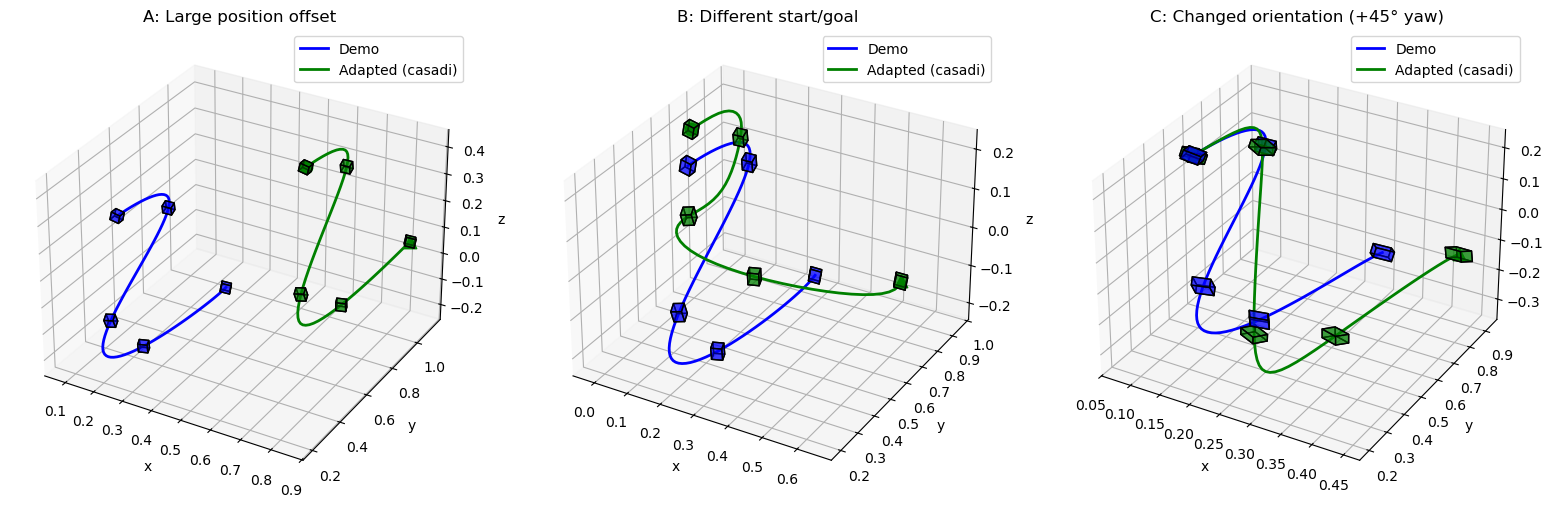

Example A solver: casadi
Example B solver: casadi
Example C solver: casadi


In [13]:
# Create multiple adapted trajectories with different boundary conditions
# Using cube visualization to show orientation changes

fig = plt.figure(figsize=(16, 5))

# --- Example A: Large position offset (pure translation) ---
ax1 = fig.add_subplot(131, projection='3d')
offset_A = np.array([0.5, 0.3, 0.2])  # Large offset
pose_init_A = {"position": positions[0].copy() + offset_A, "quaternion": quaternions[0].copy()}
pose_goal_A = {"position": positions[-1].copy() + offset_A, "quaternion": quaternions[-1].copy()}
result_A = generate_trajectory(positions, quaternions, pose_init_A, pose_goal_A, traj_length=60, use_casadi=True)

# Plot with cubes
plot_se3_trajectories(
    {"Demo": {"positions": positions, "quaternions": quaternions},
     f"Adapted ({result_A['solver']})": {"positions": result_A["adapted_pos_data"], "quaternions": result_A["adapted_quat_data"]}},
    ax=ax1, show_orientation=True, vis_type="cube", box_size_scale=0.03, num_frames=5, show_legend=True, title="A: Large position offset"
)
ax1.scatter(*pose_init_A["position"], color='green', s=80, marker='o', zorder=10)
ax1.scatter(*pose_goal_A["position"], color='green', s=80, marker='^', zorder=10)

# --- Example B: Different start and goal (stretch/warp) ---
ax2 = fig.add_subplot(132, projection='3d')
pose_init_B = {"position": positions[0].copy() + np.array([-0.1, 0.2, 0.0]), "quaternion": quaternions[0].copy()}
pose_goal_B = {"position": positions[-1].copy() + np.array([0.3, -0.1, 0.1]), "quaternion": quaternions[-1].copy()}
result_B = generate_trajectory(positions, quaternions, pose_init_B, pose_goal_B, traj_length=60, use_casadi=True)

plot_se3_trajectories(
    {"Demo": {"positions": positions, "quaternions": quaternions},
     f"Adapted ({result_B['solver']})": {"positions": result_B["adapted_pos_data"], "quaternions": result_B["adapted_quat_data"]}},
    ax=ax2, show_orientation=True, vis_type="cube", box_size_scale=0.03, num_frames=5, show_legend=True, title="B: Different start/goal"
)
ax2.scatter(*pose_init_B["position"], color='green', s=80, marker='o', zorder=10)
ax2.scatter(*pose_goal_B["position"], color='green', s=80, marker='^', zorder=10)

# --- Example C: Changed initial orientation (rotation change) ---
ax3 = fig.add_subplot(133, projection='3d')
angle_z = np.pi / 4  # 45 degrees around z-axis
quat_rot = np.array([np.cos(angle_z/2), 0, 0, np.sin(angle_z/2)])  # wxyz
pose_init_C = {"position": positions[0].copy(), "quaternion": geom.quat_multiply(quat_rot, quaternions[0])}
pose_goal_C = {"position": positions[-1].copy() + np.array([0.1, 0.1, 0.0]), "quaternion": geom.quat_multiply(quat_rot, quaternions[-1])}
result_C = generate_trajectory(positions, quaternions, pose_init_C, pose_goal_C, traj_length=60, use_casadi=True)

plot_se3_trajectories(
    {"Demo": {"positions": positions, "quaternions": quaternions},
     f"Adapted ({result_C['solver']})": {"positions": result_C["adapted_pos_data"], "quaternions": result_C["adapted_quat_data"]}},
    ax=ax3, show_orientation=True, vis_type="cube", box_size_scale=0.03, num_frames=5, show_legend=True, title="C: Changed orientation (+45° yaw)"
)
ax3.scatter(*pose_init_C["position"], color='green', s=80, marker='o', zorder=10)
ax3.scatter(*pose_goal_C["position"], color='green', s=80, marker='^', zorder=10)

plt.tight_layout()
plt.show()

print(f"Example A solver: {result_A['solver']}")
print(f"Example B solver: {result_B['solver']}")
print(f"Example C solver: {result_C['solver']}")

In [16]:
# Quantitative analysis: verify boundary constraints are satisfied
print("=== Boundary constraint verification ===")
for name, result, pose_init, pose_goal in [
    ("A", result_A, pose_init_A, pose_goal_A),
    ("B", result_B, pose_init_B, pose_goal_B),
    ("C", result_C, pose_init_C, pose_goal_C),
]:
    pos_start_err = np.linalg.norm(result["adapted_pos_data"][0] - pose_init["position"])
    pos_end_err = np.linalg.norm(result["adapted_pos_data"][-1] - pose_goal["position"])
    print(f"Example {name}: start error = {pos_start_err:.6f}, end error = {pos_end_err:.6f}")

=== Boundary constraint verification ===
Example A: start error = 0.000000, end error = 0.000000
Example B: start error = 0.000000, end error = 0.000000
Example C: start error = 0.000000, end error = 0.000000


### 6.2 Extreme adaptation scenarios

Let's push the limits with more extreme scenarios to demonstrate the **robustness** of the CasADi NLP solver:
1. **Mirror/flip** — the goal is before the start (reversed direction)
2. **Scale change** — double the spatial extent
3. **Multi-axis offset** — large offset in all directions with rotation

In [ ]:
# Extreme adaptation scenarios with cube visualization
fig = plt.figure(figsize=(16, 5))

# --- Example D: Reversed direction (goal before start) ---
ax1 = fig.add_subplot(131, projection='3d')
pose_init_D = {"position": positions[-1].copy(), "quaternion": quaternions[-1].copy()}  # Swap!
pose_goal_D = {"position": positions[0].copy(), "quaternion": quaternions[0].copy()}
result_D = generate_trajectory(positions, quaternions, pose_init_D, pose_goal_D, traj_length=60, use_casadi=True)

plot_se3_trajectories(
    {"Demo": {"positions": positions, "quaternions": quaternions},
     f"Reversed ({result_D['solver']})": {"positions": result_D["adapted_pos_data"], "quaternions": result_D["adapted_quat_data"]}},
    ax=ax1, show_orientation=True, vis_type="cube", box_size_scale=0.03, num_frames=5, show_legend=True, title="D: Reversed direction"
)
ax1.scatter(*pose_init_D["position"], color='cyan', s=80, marker='o', label='Start (was end)', zorder=10)
ax1.scatter(*pose_goal_D["position"], color='cyan', s=80, marker='^', label='Goal (was start)', zorder=10)

# --- Example E: Scale change (double spatial extent) ---
ax2 = fig.add_subplot(132, projection='3d')
scale = 2.0
center = positions.mean(axis=0)
pos_scaled_start = center + scale * (positions[0] - center)
pos_scaled_end = center + scale * (positions[-1] - center)
pose_init_E = {"position": pos_scaled_start, "quaternion": quaternions[0].copy()}
pose_goal_E = {"position": pos_scaled_end, "quaternion": quaternions[-1].copy()}
result_E = generate_trajectory(positions, quaternions, pose_init_E, pose_goal_E, traj_length=60, use_casadi=True)

plot_se3_trajectories(
    {"Demo": {"positions": positions, "quaternions": quaternions},
     f"Scaled 2x ({result_E['solver']})": {"positions": result_E["adapted_pos_data"], "quaternions": result_E["adapted_quat_data"]}},
    ax=ax2, show_orientation=True, vis_type="cube", box_size_scale=0.03, num_frames=5, show_legend=True, title="E: Scaled 2x from center"
)
ax2.scatter(*pose_init_E["position"], color='orange', s=80, marker='o', zorder=10)
ax2.scatter(*pose_goal_E["position"], color='orange', s=80, marker='^', zorder=10)

# --- Example F: Large multi-axis offset with rotation ---
ax3 = fig.add_subplot(133, projection='3d')
offset_F = np.array([1.0, -0.5, 0.3])
angle_y = np.pi / 6  # 30 degrees around y
quat_rot_F = np.array([np.cos(angle_y/2), 0, np.sin(angle_y/2), 0])  # wxyz
pose_init_F = {"position": positions[0].copy() + offset_F, "quaternion": geom.quat_multiply(quat_rot_F, quaternions[0])}
pose_goal_F = {"position": positions[-1].copy() + offset_F + np.array([0.2, 0.2, 0.1]), "quaternion": geom.quat_multiply(quat_rot_F, quaternions[-1])}
result_F = generate_trajectory(positions, quaternions, pose_init_F, pose_goal_F, traj_length=60, use_casadi=True)

plot_se3_trajectories(
    {"Demo": {"positions": positions, "quaternions": quaternions},
     f"Offset+rot ({result_F['solver']})": {"positions": result_F["adapted_pos_data"], "quaternions": result_F["adapted_quat_data"]}},
    ax=ax3, show_orientation=True, vis_type="cube", box_size_scale=0.03, num_frames=5, show_legend=True, title="F: Large offset + 30° pitch"
)
ax3.scatter(*pose_init_F["position"], color='brown', s=80, marker='o', zorder=10)
ax3.scatter(*pose_goal_F["position"], color='brown', s=80, marker='^', zorder=10)

plt.tight_layout()
plt.show()

print(f"\n=== Extreme scenarios results ===")
for name, result, pi, pg in [("D", result_D, pose_init_D, pose_goal_D), ("E", result_E, pose_init_E, pose_goal_E), ("F", result_F, pose_init_F, pose_goal_F)]:
    se = np.linalg.norm(result["adapted_pos_data"][0] - pi["position"])
    ee = np.linalg.norm(result["adapted_pos_data"][-1] - pg["position"])
    print(f"Example {name}: solver={result['solver']}, start_err={se:.6f}, end_err={ee:.6f}")

---
## 7. Optional: VLA tokenization (DHB-Token)

For **Vision-Language-Action** (VLA) models, continuous invariants can be **tokenized** into **discrete token indices** using a causal VQ-VAE. This enables:

1. **Autoregressive action generation** — predict next token conditioned on vision/language
2. **Efficient storage** — compress trajectories to compact token sequences
3. **Retrieval** — find similar motions via token-based search
4. **Multi-modal learning** — combine with visual/language tokens

### Architecture

```
Invariants (B, T, 8) → CausalConv1D Encoder → Latent z (B, T, D) → VQ Codebook → Tokens (B, T)
                                                                              ↓
                                            Reconstructed (B, T, 8) ← CausalConv1D Decoder ← z_q
```

The **VectorQuantizer** maps each latent vector to the nearest codebook entry, producing discrete tokens.

**Requires:** `torch`. To install: `pip install torch` or use the `gpu` pixi environment.

In [19]:
try:
    import torch
    from dhb_xr.tokenization.vqvae import DHBTokenizer
    
    print("=== VLA Tokenization Demo ===\n")
    
    # Prepare invariants
    inv_combined = np.concatenate([linear_inv, angular_inv], axis=1).astype(np.float32)
    x = torch.from_numpy(inv_combined).unsqueeze(0)  # (1, T, 8)
    T_seq = x.shape[1]
    
    # Create tokenizer
    codebook_size = 64
    latent_dim = 16
    model = DHBTokenizer(invariant_dim=8, latent_dim=latent_dim, codebook_size=codebook_size)
    
    # Forward pass
    indices, reconstructed, z, z_q = model(x)
    
    print(f"Input invariants: {x.shape} (batch, time, features)")
    print(f"Latent z: {z.shape}")
    print(f"Token indices: {indices.shape}, unique tokens: {len(torch.unique(indices))}/{codebook_size}")
    print(f"Reconstructed: {reconstructed.shape}")
    
    # Compute reconstruction error
    rec_mse = torch.nn.functional.mse_loss(reconstructed, x).item()
    print(f"\nReconstruction MSE: {rec_mse:.6f}")
    
    # Per-step error
    per_step_mse = ((reconstructed - x) ** 2).mean(dim=2).squeeze().detach().numpy()
    
    HAS_TORCH = True
except ImportError as e:
    print(f"Skipping VLA tokenization (torch required): {e}")
    HAS_TORCH = False

Invariants shape: torch.Size([1, 82, 8])
Token indices shape: torch.Size([1, 82])
Reconstructed shape: torch.Size([1, 82, 8])
Sample tokens (first 8): [54, 57, 0, 42, 30, 54, 54, 54]
Reconstruction MSE: 0.0435197651386261


In [ ]:
if HAS_TORCH:
    # Plot 1: Original vs Reconstructed Invariants
    fig, axes = plt.subplots(2, 4, figsize=(16, 6))
    fig.suptitle('Invariant Reconstruction: Original (blue) vs Tokenized→Decoded (orange, dashed)', fontsize=12)
    
    inv_names = ['lin_mag', 'lin_θ1', 'lin_θ2', 'lin_θ3', 'ang_mag', 'ang_θ1', 'ang_θ2', 'ang_θ3']
    x_np = x.squeeze().detach().numpy()
    rec_np = reconstructed.squeeze().detach().numpy()
    
    for j in range(8):
        row, col = j // 4, j % 4
        axes[row, col].plot(x_np[:, j], 'b-', alpha=0.8, label='Original')
        axes[row, col].plot(rec_np[:, j], 'orange', linestyle='--', alpha=0.8, label='Reconstructed')
        axes[row, col].set_title(inv_names[j])
        axes[row, col].set_xlabel('step')
        if j == 0:
            axes[row, col].legend(fontsize=8)
    
    plt.tight_layout()
    plt.show()

In [ ]:
if HAS_TORCH:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    # Plot 2a: Token sequence visualization
    token_seq = indices.squeeze().detach().numpy()
    axes[0].bar(range(len(token_seq)), token_seq, color='steelblue', alpha=0.8)
    axes[0].set_xlabel('Time step')
    axes[0].set_ylabel('Token index')
    axes[0].set_title(f'Token Sequence (vocabulary size={codebook_size})')
    axes[0].set_ylim(0, codebook_size)
    
    # Plot 2b: Token frequency histogram
    unique, counts = np.unique(token_seq, return_counts=True)
    axes[1].bar(unique, counts, color='teal', alpha=0.8)
    axes[1].set_xlabel('Token index')
    axes[1].set_ylabel('Frequency')
    axes[1].set_title(f'Token Histogram ({len(unique)} unique tokens used)')
    
    # Plot 2c: Per-step reconstruction error
    axes[2].plot(per_step_mse, 'r-', alpha=0.8)
    axes[2].fill_between(range(len(per_step_mse)), per_step_mse, alpha=0.3, color='red')
    axes[2].set_xlabel('Time step')
    axes[2].set_ylabel('MSE')
    axes[2].set_title('Reconstruction Error Over Time')
    axes[2].axhline(y=per_step_mse.mean(), color='k', linestyle='--', label=f'Mean: {per_step_mse.mean():.4f}')
    axes[2].legend()
    
    plt.tight_layout()
    plt.show()

In [ ]:
if HAS_TORCH:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Plot 3a: Codebook heatmap
    codebook = model.vq.embedding.weight.detach().numpy()  # (codebook_size, latent_dim)
    im = axes[0].imshow(codebook.T, aspect='auto', cmap='viridis')
    axes[0].set_xlabel('Codebook entry index')
    axes[0].set_ylabel('Latent dimension')
    axes[0].set_title(f'Codebook Visualization ({codebook_size} × {latent_dim})')
    plt.colorbar(im, ax=axes[0], label='Value')
    
    # Highlight used tokens
    used_tokens = np.unique(token_seq)
    for tok in used_tokens:
        axes[0].axvline(x=tok, color='red', alpha=0.3, linewidth=1)
    axes[0].set_xlim(-0.5, codebook_size - 0.5)
    
    # Plot 3b: Latent space visualization (2 principal dimensions)
    z_np = z.squeeze().detach().numpy()  # (T, latent_dim)
    z_q_np = z_q.squeeze().detach().numpy()
    
    # Simple 2D projection using first 2 dimensions (no sklearn dependency)
    # Or use SVD-based PCA if numpy
    try:
        # Center the data
        combined = np.vstack([z_np, z_q_np])
        mean = combined.mean(axis=0)
        centered = combined - mean
        # SVD for PCA
        U, S, Vt = np.linalg.svd(centered, full_matrices=False)
        combined_2d = centered @ Vt[:2].T
        z_2d = combined_2d[:len(z_np)]
        z_q_2d = combined_2d[len(z_np):]
        explained_var = (S[:2]**2).sum() / (S**2).sum()
        pca_label = f'PC1 & PC2 ({explained_var:.0%} var)'
    except Exception:
        # Fallback: just use first 2 dimensions
        z_2d = z_np[:, :2]
        z_q_2d = z_q_np[:, :2]
        pca_label = 'Dim 0 & 1'
    
    # Color by time
    colors = np.arange(len(z_2d))
    axes[1].scatter(z_2d[:, 0], z_2d[:, 1], c=colors, cmap='Blues', alpha=0.7, s=40, label='z (encoder)')
    axes[1].scatter(z_q_2d[:, 0], z_q_2d[:, 1], c=colors, cmap='Oranges', alpha=0.7, s=40, marker='x', label='z_q (quantized)')
    # Draw lines connecting z to z_q
    for j in range(0, len(z_2d), 5):  # Every 5th point
        axes[1].plot([z_2d[j, 0], z_q_2d[j, 0]], [z_2d[j, 1], z_q_2d[j, 1]], 'k-', alpha=0.3, linewidth=0.5)
    axes[1].set_xlabel(pca_label.split('&')[0].strip())
    axes[1].set_ylabel(pca_label.split('&')[1].strip() if '&' in pca_label else 'Dim 1')
    axes[1].set_title(f'Latent Space: z → z_q ({pca_label})')
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()

### Key observations

1. **Reconstruction quality**: The VQ-VAE captures the main structure of invariants, with higher error at rapid transitions
2. **Codebook utilization**: Not all tokens are used equally — some are more common (representing typical motion patterns)
3. **Latent quantization**: PCA shows how encoder outputs (z) are mapped to nearest codebook vectors (z_q)

### ⚠️ Why is reconstruction error so high?

**The model is untrained!** The `DHBTokenizer` shown here uses **random weights**. In practice:

| Condition | Expected Position Error |
|-----------|------------------------|
| **Untrained (random)** | 1.0 – 5.0+ (meaningless reconstruction) |
| **Trained (small dataset)** | 0.05 – 0.2 |
| **Trained (large dataset)** | < 0.01 |

To train the VQ-VAE:
```python
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
for batch in dataloader:
    indices, reconstructed, z, z_q = model(batch)
    loss = model.loss(batch, reconstructed, z, z_q, beta=0.25)
    loss.backward()
    optimizer.step()
```

### Causal streaming for VLA

The encoder uses **causal convolutions** (no future information), so tokens can be generated **step-by-step** as new observations arrive:

```python
# Streaming tokenization (pseudo-code)
for t in range(T):
    invariant_t = encode_dhb_dr_step(pose_t, pose_{t-1}, ...)  # Get new invariant
    token_t = tokenizer.encode_step(invariant_t)              # Tokenize causally
    next_token = vla_model.predict(vision, language, tokens[:t+1])  # Predict next
```

This enables **real-time action generation** in VLA systems.

In [ ]:
if HAS_TORCH:
    # Decode tokens back to trajectory
    print("=== Token → Trajectory Reconstruction ===")
    print("⚠️  NOTE: Model is UNTRAINED (random weights) — high reconstruction error is expected!")
    print("    A trained VQ-VAE on motion data would achieve much lower error.\n")
    
    # Get reconstructed invariants
    lin_inv_rec = rec_np[:, :4]
    ang_inv_rec = rec_np[:, 4:]
    
    # Decode to trajectory
    init_pose = {"position": positions[0].copy(), "quaternion": quaternions[0].copy()}
    traj_rec = decode_dhb_dr(lin_inv_rec, ang_inv_rec, init_pose, method="pos", drop_padded=True)
    pos_rec = traj_rec["positions"]
    quat_rec = traj_rec["quaternions"]
    
    # Plot original vs token-reconstructed trajectory
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    # Trim to same length
    n_plot = min(len(positions), len(pos_rec))
    
    ax.plot(positions[:n_plot, 0], positions[:n_plot, 1], positions[:n_plot, 2], 'b-', linewidth=2, alpha=0.7, label='Original')
    ax.plot(pos_rec[:n_plot, 0], pos_rec[:n_plot, 1], pos_rec[:n_plot, 2], 'orange', linestyle='--', linewidth=2, alpha=0.8, label='From Tokens (untrained)')
    
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')
    ax.set_title('Trajectory: Original vs Reconstructed from Tokens\n(Random model — training required for accurate reconstruction)')
    ax.legend()
    plt.tight_layout()
    plt.show()
    
    pos_error = np.linalg.norm(positions[:n_plot] - pos_rec[:n_plot], axis=1)
    print(f"Position error — mean: {pos_error.mean():.4f}, max: {pos_error.max():.4f}")
    print(f"  → With training, expect mean error < 0.01 for smooth trajectories")
    print(f"\nTokenization compression: {T_seq} steps × 8 floats → {T_seq} tokens ({T_seq * 8 * 4 / 1024:.2f} KB → {T_seq * 1:.0f} bytes)")

### Training the VQ-VAE

Let's train the tokenizer on this trajectory to see how reconstruction improves. We'll:
1. Generate multiple augmented versions of the trajectory (with noise, scaling)
2. Train for 200 epochs
3. Compare reconstruction before vs after training

In [ ]:
if HAS_TORCH:
    import torch.optim as optim
    
    # Create a fresh model for training demo
    model_trained = DHBTokenizer(invariant_dim=8, latent_dim=16, codebook_size=64)
    optimizer = optim.Adam(model_trained.parameters(), lr=3e-3)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=300, eta_min=1e-5)
    
    # Data augmentation: create variations of the trajectory
    def augment_invariants(inv, n_aug=20):
        """Create augmented versions with noise and scaling."""
        augmented = [inv]
        for _ in range(n_aug - 1):
            noise = np.random.randn(*inv.shape) * 0.02  # Small noise
            scale = np.random.uniform(0.9, 1.1)
            augmented.append(inv * scale + noise)
        return np.stack(augmented, axis=0).astype(np.float32)
    
    # Create training batch
    train_data = augment_invariants(inv_combined, n_aug=32)
    train_tensor = torch.from_numpy(train_data)  # (32, T, 8)
    
    print(f"Training data shape: {train_tensor.shape}")
    print(f"Training for 300 epochs with cosine LR schedule...")
    
    # Training loop
    losses = []
    best_loss = float('inf')
    best_state = None
    for epoch in range(300):
        optimizer.zero_grad()
        indices, reconstructed, z, z_q = model_trained(train_tensor)
        loss = model_trained.loss(train_tensor, reconstructed, z, z_q, beta=0.25)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_trained.parameters(), 1.0)  # Gradient clipping
        optimizer.step()
        scheduler.step()
        losses.append(loss.item())
        
        # Save best model
        if loss.item() < best_loss:
            best_loss = loss.item()
            best_state = {k: v.clone() for k, v in model_trained.state_dict().items()}
        
        if (epoch + 1) % 100 == 0:
            print(f"  Epoch {epoch+1}: loss = {loss.item():.4f}, lr = {scheduler.get_last_lr()[0]:.2e}")
    
    # Load best model
    model_trained.load_state_dict(best_state)
    print(f"\nTraining complete! Best loss: {best_loss:.4f}")

In [ ]:
if HAS_TORCH:
    # Compare trained vs untrained on original trajectory
    x_single = torch.from_numpy(inv_combined.astype(np.float32)).unsqueeze(0)
    
    # Untrained model (from before)
    with torch.no_grad():
        _, rec_untrained, _, _ = model(x_single)
        _, rec_trained, _, _ = model_trained(x_single)
    
    mse_untrained = torch.nn.functional.mse_loss(rec_untrained, x_single).item()
    mse_trained = torch.nn.functional.mse_loss(rec_trained, x_single).item()
    
    print("=== Invariant Reconstruction MSE ===")
    print(f"  Untrained: {mse_untrained:.4f}")
    print(f"  Trained:   {mse_trained:.4f}")
    print(f"  Improvement: {mse_untrained/mse_trained:.1f}x better")
    
    # Plot comparison
    fig, axes = plt.subplots(2, 4, figsize=(16, 6))
    fig.suptitle('Trained VQ-VAE: Original (blue) vs Reconstructed (green)', fontsize=12)
    
    inv_names = ['lin_mag', 'lin_θ1', 'lin_θ2', 'lin_θ3', 'ang_mag', 'ang_θ1', 'ang_θ2', 'ang_θ3']
    x_np = x_single.squeeze().numpy()
    rec_trained_np = rec_trained.squeeze().detach().numpy()
    
    for j in range(8):
        row, col = j // 4, j % 4
        axes[row, col].plot(x_np[:, j], 'b-', alpha=0.8, linewidth=2, label='Original')
        axes[row, col].plot(rec_trained_np[:, j], 'g--', alpha=0.8, linewidth=2, label='Trained')
        axes[row, col].set_title(inv_names[j])
        axes[row, col].set_xlabel('step')
        if j == 0:
            axes[row, col].legend(fontsize=8)
    
    plt.tight_layout()
    plt.show()

In [ ]:
if HAS_TORCH:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    # Loss curve
    axes[0].plot(losses, 'b-', alpha=0.7)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training Loss')
    axes[0].set_yscale('log')
    axes[0].grid(True, alpha=0.3)
    
    # Token usage after training
    with torch.no_grad():
        indices_trained, _, _, _ = model_trained(x_single)
    token_seq_trained = indices_trained.squeeze().numpy()
    unique_trained, counts_trained = np.unique(token_seq_trained, return_counts=True)
    
    axes[1].bar(unique_trained, counts_trained, color='green', alpha=0.8)
    axes[1].set_xlabel('Token index')
    axes[1].set_ylabel('Frequency')
    axes[1].set_title(f'Trained Token Histogram ({len(unique_trained)} unique tokens)')
    
    plt.tight_layout()
    plt.show()

In [ ]:
if HAS_TORCH:
    # Decode trained model's output to trajectory
    lin_inv_trained = rec_trained_np[:, :4]
    ang_inv_trained = rec_trained_np[:, 4:]
    
    init_pose = {"position": positions[0].copy(), "quaternion": quaternions[0].copy()}
    traj_trained = decode_dhb_dr(lin_inv_trained, ang_inv_trained, init_pose, method="pos", drop_padded=True)
    pos_trained = traj_trained["positions"]
    
    # Plot comparison: original vs untrained vs trained
    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    n_plot = min(len(positions), len(pos_rec), len(pos_trained))
    
    ax.plot(positions[:n_plot, 0], positions[:n_plot, 1], positions[:n_plot, 2], 
            'b-', linewidth=2.5, alpha=0.9, label='Original')
    ax.plot(pos_rec[:n_plot, 0], pos_rec[:n_plot, 1], pos_rec[:n_plot, 2], 
            'orange', linestyle=':', linewidth=2, alpha=0.6, label='Untrained')
    ax.plot(pos_trained[:n_plot, 0], pos_trained[:n_plot, 1], pos_trained[:n_plot, 2], 
            'g--', linewidth=2, alpha=0.9, label='Trained (200 epochs)')
    
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')
    ax.set_title('Trajectory Reconstruction: Original vs Untrained vs Trained')
    ax.legend()
    plt.tight_layout()
    plt.show()
    
    # Error comparison
    err_untrained = np.linalg.norm(positions[:n_plot] - pos_rec[:n_plot], axis=1)
    err_trained = np.linalg.norm(positions[:n_plot] - pos_trained[:n_plot], axis=1)
    
    print("=== Position Error Comparison ===")
    print(f"  Untrained: mean={err_untrained.mean():.4f}, max={err_untrained.max():.4f}")
    print(f"  Trained:   mean={err_trained.mean():.4f}, max={err_trained.max():.4f}")
    print(f"  Improvement: {err_untrained.mean()/err_trained.mean():.1f}x better")

---
## Summary

| Feature | Use-case |
|--------|----------|
| **DHB-DR / DHB-QR** | Encode/decode SE(3) trajectories; invariants are frame-independent |
| **SE(3) invariance** | Compare motions across different reference frames |
| **DHB-TI** | Robustness to execution speed and sampling rate (reparameterize by progress) |
| **Trajectory adaptation** | Retarget a demo to new start/goal poses (same motion, new boundaries) |
| **Tokenization** | Discrete action representation for VLAs |

See the **examples/** scripts and **docs/examples_walkthrough.md** for more.